In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [7]:
print(df.dtypes)

Дата              str
Склад           int64
Контрагент        str
Номенклатура      str
Количество      int64
dtype: object


Сразу переведем столбец "Дата" в правильный формат

In [8]:
df['Дата'] = pd.to_datetime(df['Дата'])

print(df['Дата'].dtype)

datetime64[us]


Сгруппируйте данные по дате, посчитайте количество продаж

In [10]:
grouped_df = df.groupby('Дата')['Количество'].sum().reset_index()

Вывести несколько первых строк сгруппированных данных

In [11]:
grouped_df.head()

,Дата,Количество
0,2018-01-04,3734
1,2018-01-05,3643
2,2018-01-06,3193
3,2018-01-07,3298
4,2018-01-09,4055


Нарисуйте график продаж у `grouped_df`

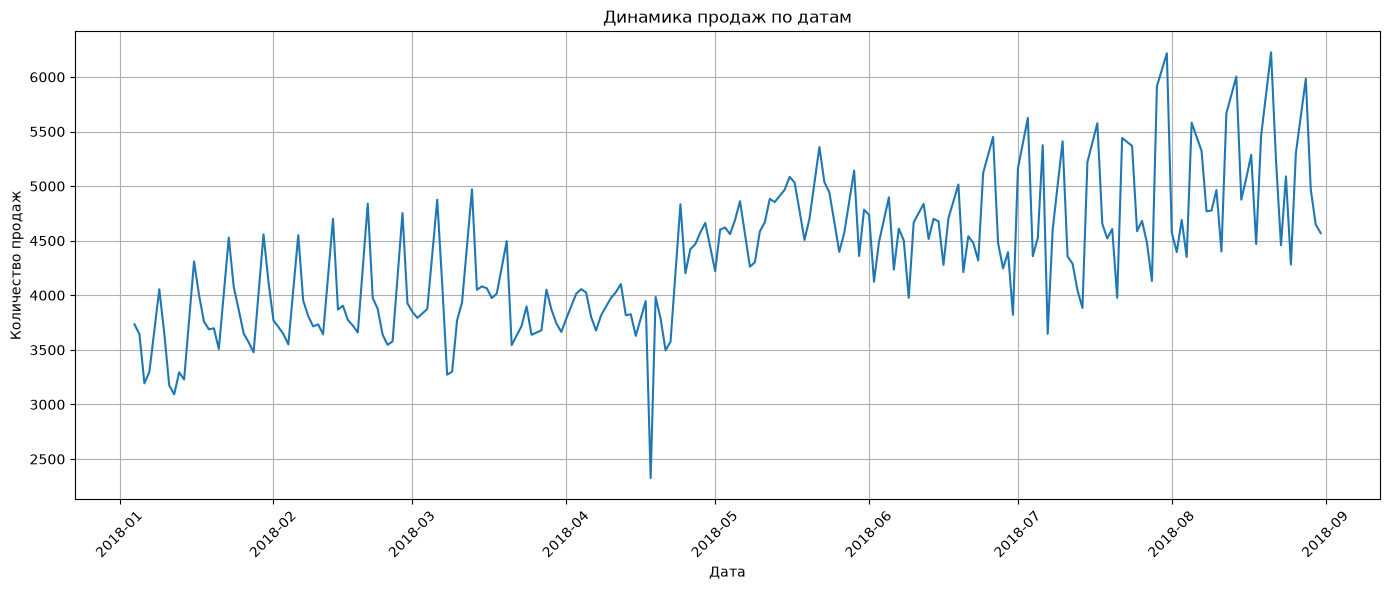

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(grouped_df['Дата'], grouped_df['Количество'])

plt.title('Динамика продаж по датам')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

### Вывод по графику динамики продаж

На графике представлена динамика ежедневного количества проданных товаров за период с января по август 2018 года.

**Основные наблюдения:**

1. Наблюдается общий восходящий тренд продаж: в начале периода ежедневные продажи составляли преимущественно 3 000–4 500 единиц, а к августу достигали 4 500–6 200 единиц.
2. В январе и феврале заметны регулярные колебания, предположительно связанные с недельной сезонностью.
3. В марте и первой половине апреля продажи относительно стабильны, без выраженного устойчивого роста.
4. В середине апреля наблюдается резкое снижение продаж примерно до 2 300 единиц, которое можно рассматривать как потенциальную аномалию.
5. С конца апреля и в мае наблюдается увеличение среднего уровня ежедневных продаж.
6. В июне, июле и августе колебания становятся более выраженными. Пиковые значения достигают приблизительно 6 200 единиц.
7. Во второй половине периода увеличивается разброс ежедневных продаж, что свидетельствует о росте их изменчивости.

**Общий вывод:** продажи демонстрируют положительную динамику, однако сопровождаются регулярными колебаниями и отдельными аномальными значениями. Для подтверждения недельной сезонности и выяснения причин резких изменений необходим дополнительный анализ по дням недели, складам и товарам.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [13]:
df.loc[df['Количество'].idxmax()]

Дата            2018-06-28 00:00:00
Склад                             1
Контрагент              address_208
Номенклатура              product_0
Количество                      200
Name: 218822, dtype: object

Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [14]:
top_product = df[
    (df['Склад'] == 3) &
    (df['Дата'].dt.month.isin([6, 7, 8])) &
    (df['Дата'].dt.dayofweek == 2)
].groupby('Номенклатура')['Количество'].sum().sort_values(ascending=False)

top_product.head(1)

Номенклатура
product_1    2267
Name: Количество, dtype: int64

Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [17]:
weather = pd.read_csv(
    'Astana Weather Archive.csv',
    sep=';',
    skiprows=6,
    encoding='utf-8',
    index_col=False
)

weather[['Местное время в Астане', 'T']].head()

,Местное время в Астане,T
0,31.08.2018 23:00,8.2
1,31.08.2018 20:00,9.6
2,31.08.2018 17:00,11.3
3,31.08.2018 14:00,12.3
4,31.08.2018 11:00,13.2


In [19]:
weather['Дата'] = pd.to_datetime(
    weather['Местное время в Астане'],
    format='%d.%m.%Y %H:%M'
).dt.normalize()

weather_daily = weather.groupby('Дата')['T'].mean().round(2).reset_index()

weather_daily.head()

,Дата,T
0,2018-01-01,-9.46
1,2018-01-02,-9.51
2,2018-01-03,-11.46
3,2018-01-04,-14.08
4,2018-01-05,-16.86


In [20]:
merged_df = pd.merge(
    grouped_df,
    weather_daily,
    on='Дата',
    how='left'
)

merged_df.head()

,Дата,Количество,T
0,2018-01-04,3734,-14.08
1,2018-01-05,3643,-16.86
2,2018-01-06,3193,-13.30
3,2018-01-07,3298,-12.75
4,2018-01-09,4055,-6.25


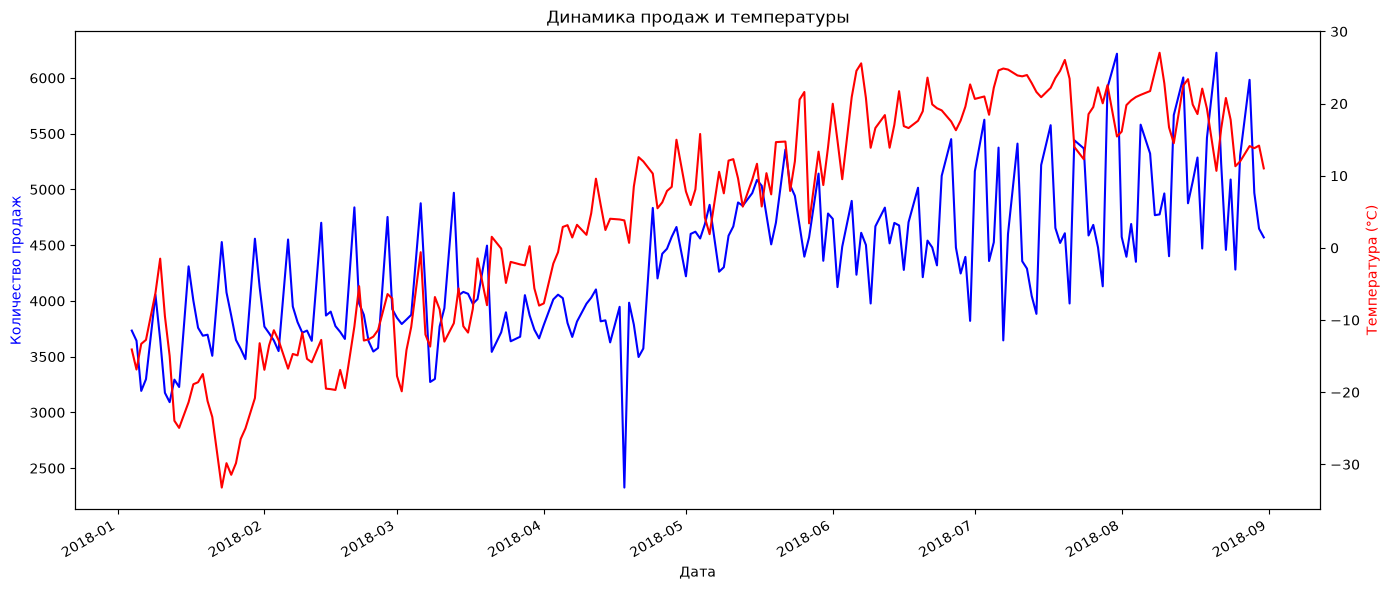

In [21]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(merged_df['Дата'], merged_df['Количество'], color='blue', label='Продажи')
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж', color='blue')

ax2 = ax1.twinx()

ax2.plot(merged_df['Дата'], merged_df['T'], color='red', label='Температура')
ax2.set_ylabel('Температура (°C)', color='red')

plt.title('Динамика продаж и температуры')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

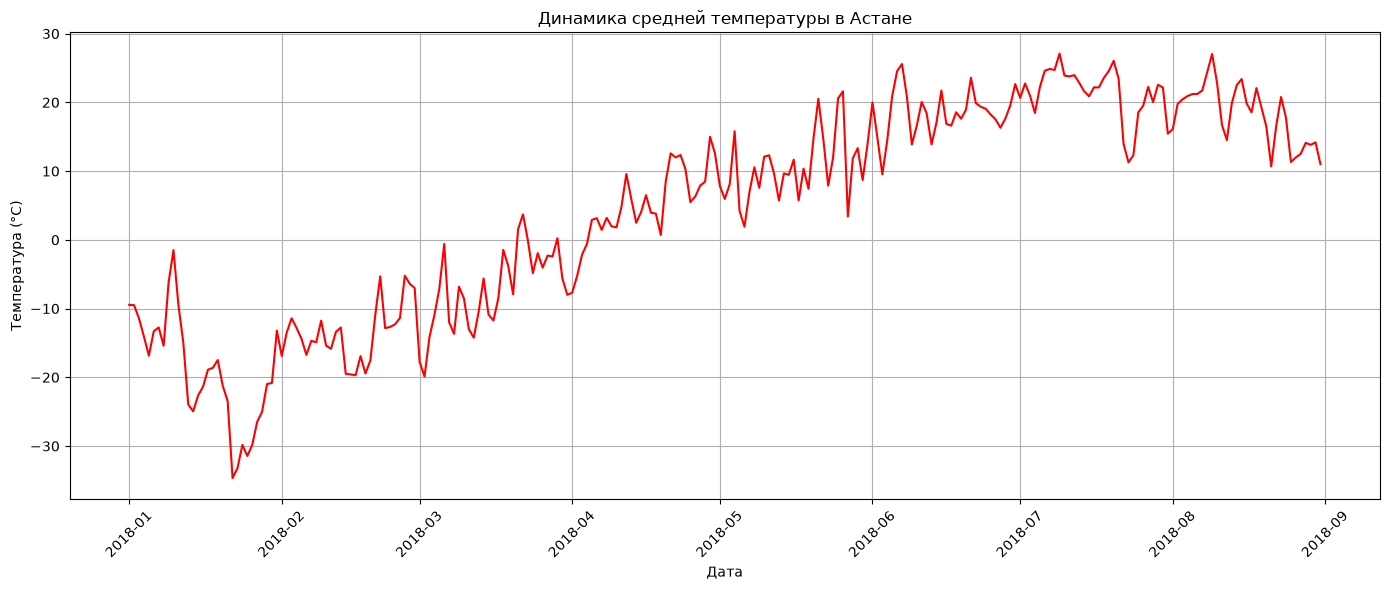

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(weather_daily['Дата'], weather_daily['T'], color='red')

plt.title('Динамика средней температуры в Астане')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Вывод по анализу продаж и температуры

За период с января по август 2018 года наблюдается общий рост количества продаж и средней температуры воздуха в Астане.

Зимой продажи преимущественно составляли 3 000–4 500 единиц в день, а летом достигали 4 500–6 200 единиц. Одновременно температура повысилась примерно с −35 °C до +27 °C.

На совместном графике заметно, что рост температуры сопровождается увеличением продаж. Это позволяет предположить наличие положительной связи между температурой и количеством продаж.

Однако продажи также характеризуются регулярными колебаниями и отдельными аномальными значениями. Следовательно, на продажи могут влиять и другие факторы: сезонность, дни недели, ассортимент товаров и особенности работы складов.

**Общий вывод:** визуальный анализ показывает возможную положительную связь между температурой и продажами, но для подтверждения этой зависимости необходим дополнительный статистический анализ.